In [ ]:
# Import packages
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linprog
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# select 5 stocks
index_name = "NVDA,AAPL,AMZN,MSFT,GOOGL"
index_stocks = index_name.split(",")
print(index_stocks)

['NVDA', 'AAPL', 'AMZN', 'MSFT', 'GOOGL']


In [ ]:
# download data
stock_tickers = index_name.replace(","," ")
print(stock_tickers)
data = yf.download(stock_tickers, start="2023-8-31", end="2026-8-31", group_by='tickers')
print(data.shape)
display(data.head())

NVDA AAPL AMZN MSFT GOOGL


[*********************100%***********************]  5 of 5 completed

(751, 25)


Ticker            AMZN                                                \
Price             Open        High         Low       Close    Volume   
Date                                                                   
2023-08-31  135.059998  138.789993  135.000000  138.009995  58781300   
2023-09-01  139.460007  139.960007  136.880005  138.119995  40991500   
2023-09-05  137.729996  137.800003  135.820007  137.270004  40636700   
2023-09-06  136.320007  137.449997  134.610001  135.360001  41785500   
2023-09-07  133.899994  138.029999  133.160004  137.850006  48498900   

Ticker           GOOGL                                                ...  \
Price             Open        High         Low       Close    Volume  ...   
Date                                                                  ...   
2023-08-31  134.727964  136.699212  134.510036  134.886459  30053800  ...   
2023-09-01  136.164323  136.164323  133.578924  134.381287  21543700  ...   
2023-09-05  134.163358  135.134117  133.311464  134.490250  19403100  ...   
2023-09-06  134.737874  135.243061  132.410019  133.192581  18684500  ...   
2023-09-07  132.330774  134.302022  131.696808  133.985031  18844300  ...   

Ticker            AAPL                                                 \
Price             Open        High         Low       Close     Volume   
Date                                                                    
2023-08-31  185.333347  186.596265  184.978151  185.362946   60794500   
2023-09-01  186.961331  187.385585  185.767471  186.931732   45766500   
2023-09-05  185.767484  187.444796  185.106427  187.168533   45280000   
2023-09-06  185.885875  186.329882  179.048361  180.469147   81755800   
2023-09-07  172.842292  175.831872  171.224177  175.190536  112488800   

Ticker            MSFT                                                
Price             Open        High         Low       Close    Volume  
Date                                                                  
2023-08-31  321.666050  323.336907  319.301420  320.259003  26411000  
2023-09-01  323.727775  324.392206  319.301448  321.138428  14942000  
2023-09-05  321.470645  327.186771  321.138430  325.916504  18553900  
2023-09-06  325.750398  326.805668  322.623620  325.261841  17535800  
2023-09-07  323.708255  325.457269  321.499967  322.359833  18381000  

[5 rows x 25 columns]

In [16]:
data_long = (
    data
    .stack('Ticker')  # 把Ticker从列索引压入行，和Date组成双索引
    .reset_index()    # 重置索引，让Date和Ticker成为普通列
    .pivot_table(     # 把Indicator转成列（Open/High/Low等）
        index=['Ticker', 'Date'],
        values=data
        .columns.levels[1],  # 指标列名
        dropna=False
    )
    .reset_index()    # 最终重置索引，得到整洁的长格式
)
# data_long = data_long.drop(columns='Adj Close')
print(data_long.columns)
data_long.columns = ['SecurityID', 'TradingDate', 'ClosePrice', 'HighPrice', 'LowPrice', 'OpenPrice', 'Volume']
data_long = data_long[['SecurityID', 'TradingDate', 'ClosePrice','Volume']]
# 按SecurityID分组，计算每个股票相对上一交易日的收益率
data_long['LnPrice'] = np.log(data_long['ClosePrice'])
data_long['Xit'] = (
    data_long
    .sort_values(['SecurityID', 'TradingDate'])  # 先排序，确保日期顺序正确
    .groupby('SecurityID')['LnPrice']
    .diff()  # 计算相对上一行的变化
)

stocks = data_long['SecurityID'].unique()
display(data_long)

Index(['Ticker', 'Date', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object', name='Price')


,SecurityID,TradingDate,ClosePrice,Volume,LnPrice,Xit
0,AAPL,2023-08-31,185.362946,60794500.0,5.222316,NaN
1,AAPL,2023-09-01,186.931732,45766500.0,5.230743,0.008428
2,AAPL,2023-09-05,187.168533,45280000.0,5.232009,0.001266
3,AAPL,2023-09-06,180.469147,81755800.0,5.195560,-0.036450
4,AAPL,2023-09-07,175.190536,112488800.0,5.165874,-0.029686
...,...,...,...,...,...,...
3750,NVDA,2026-08-24,208.246979,135187300.0,5.338725,-0.029492
3751,NVDA,2026-08-25,212.811874,122309000.0,5.360409,0.021684
3752,NVDA,2026-08-26,209.425659,179900000.0,5.344369,-0.016040
3753,NVDA,2026-08-27,227.725174,298909800.0,5.428140,0.083771


In [ ]:
# -------------------------------------------------------------
# 步骤 1: 确定基准日 t (2023-08-31) 并计算组合价值 V_t
# -------------------------------------------------------------
# 设定每只股票持股数 lambda_i = 100
lambda_shares = pd.Series(100.0, index=index_stocks, name="Shares")

# 提取基准日 t 的收盘价 S_{t, i}
base_date = pd.to_datetime("2023-08-31")
t_prices = (
    data_long[data_long["TradingDate"] == base_date]
    .set_index("SecurityID")["ClosePrice"]
    .reindex(index_stocks)
)

# 计算各资产市值与组合总价值 V_t
asset_values_t = lambda_shares * t_prices
V_t = asset_values_t.sum()

print("=" * 50)
print(f"基准日 t ({base_date.strftime('%Y-%m-%d')}) 投资组合总价值 V_t: ${V_t:,.2f}")
print("=" * 50)

# -------------------------------------------------------------
# 步骤 2 & 3: 计算市值权重 w_{t, i}、向量 b_t 与标量 c_t
# -------------------------------------------------------------
# 计算市值权重 w_{t, i}
w_t = asset_values_t / V_t

# 对应一阶近似系数: L_{t+1}^\Delta = -(c_t + b_t' * X_{t+1})
c_t = 0.0
b_t = asset_values_t.copy()  # b_{t, i} = lambda_i * S_{t, i} = V_t * w_{t, i}

portfolio_summary = pd.DataFrame(
    {
        "Shares": lambda_shares,
        "Price S_t": t_prices,
        "Market Value (b_t)": b_t,
        "Weight (w_t)": w_t,
    }
)
display(portfolio_summary)

print(f"常数项 c_t: {c_t}")
print(f"权重向量 b_t:\n{b_t.to_dict()}")

# -------------------------------------------------------------
# 步骤 4: 估计 X_{t+1} 的联合分布函数 (多元正态分布参数估计)
# -------------------------------------------------------------
# 转换为以日期为索引、各资产收益率为列的宽表格矩阵 (排除缺失的第1天 diff)
X_matrix = (
    data_long.dropna(subset=["Xit"])
    .pivot(index="TradingDate", columns="SecurityID", values="Xit")[index_stocks]
)

# 估计均值向量 mu (d 维) 与 协方差矩阵 Sigma (d x d)
n_obs = len(X_matrix)
mu_hat = X_matrix.mean()
Sigma_hat = X_matrix.cov()  # 默认使用 ddof=1 无偏估计

print("\n" + "=" * 50)
print(f"样本期有效交易日观测数: {n_obs}")
print("\n估计的日期望收益率向量 mu_hat:")
print(mu_hat)
print("\n估计的日收益率协方差矩阵 Sigma_hat:")
display(Sigma_hat)

# -------------------------------------------------------------
# 步骤 5: 导出组合一阶近似损失分布与下一期 (t+1) 实际近似损失
# -------------------------------------------------------------
# 理论分布: L_{t+1}^\Delta ~ N(-b_t' * mu, b_t' * Sigma * b_t)
b_vec = b_t.values
loss_mean = -np.dot(b_vec, mu_hat.values)
loss_variance = np.dot(b_vec, np.dot(Sigma_hat.values, b_vec))
loss_std = np.sqrt(loss_variance)

print("\n" + "=" * 50)
print(f"组合日近似损失的期望值 E[L]: ${loss_mean:.4f}")
print(f"组合日近似损失的标准差 Std[L]: ${loss_std:.4f}")
print(f"理论损失分布: L ~ N({loss_mean:.2f}, {loss_std:.2f}^2)")

# 验证 t+1 日 (下一个交易日 2023-09-01) 的近似损失
trading_dates = sorted(data_long["TradingDate"].unique())
t_plus_1_date = trading_dates[trading_dates.index(base_date) + 1]

X_t_plus_1 = X_matrix.loc[t_plus_1_date]
approx_loss_t_plus_1 = -(c_t + np.dot(b_vec, X_t_plus_1.values))

print(
    f"\n基准日次日 ({pd.to_datetime(t_plus_1_date).strftime('%Y-%m-%d')}) 的一阶近似损失 L_(t+1): ${approx_loss_t_plus_1:.2f}"
)

基准日 t (2023-08-31) 投资组合总价值 V_t: $82,772.24


,Shares (lambda),Price S_t,Market Value (b_t),Weight (w_t)
NVDA,100.0,49.203983,4920.398331,0.059445
AAPL,100.0,185.362946,18536.294556,0.223943
AMZN,100.0,138.009995,13800.999451,0.166735
MSFT,100.0,320.259003,32025.900269,0.386916
GOOGL,100.0,134.886459,13488.645935,0.162961


常数项 c_t: 0.0
权重向量 b_t:
{'NVDA': 4920.398330688477, 'AAPL': 18536.294555664062, 'AMZN': 13800.999450683594, 'MSFT': 32025.900268554688, 'GOOGL': 13488.645935058594}

样本期有效交易日观测数: 750

估计的日期望收益率向量 mu_hat:
SecurityID
NVDA     0.001980
AAPL     0.000727
AMZN     0.000877
MSFT     0.000630
GOOGL    0.001257
dtype: float64

估计的日收益率协方差矩阵 Sigma_hat:


SecurityID,NVDA,AAPL,AMZN,MSFT,GOOGL
SecurityID,,,,,
NVDA,0.000871,0.000152,0.000264,0.000207,0.000211
AAPL,0.000152,0.000284,0.000128,0.000096,0.000116
AMZN,0.000264,0.000128,0.000410,0.000176,0.000220
MSFT,0.000207,0.000096,0.000176,0.000268,0.000111
GOOGL,0.000211,0.000116,0.000220,0.000111,0.000369



组合日近似损失的期望值 E[L]: $-72.4436
组合日近似损失的标准差 Std[L]: $1125.7177
理论损失分布: L ~ N(-72.44, 1125.72^2)

基准日次日 (2023-09-01) 的一阶近似损失 L_(t+1): $-119.35


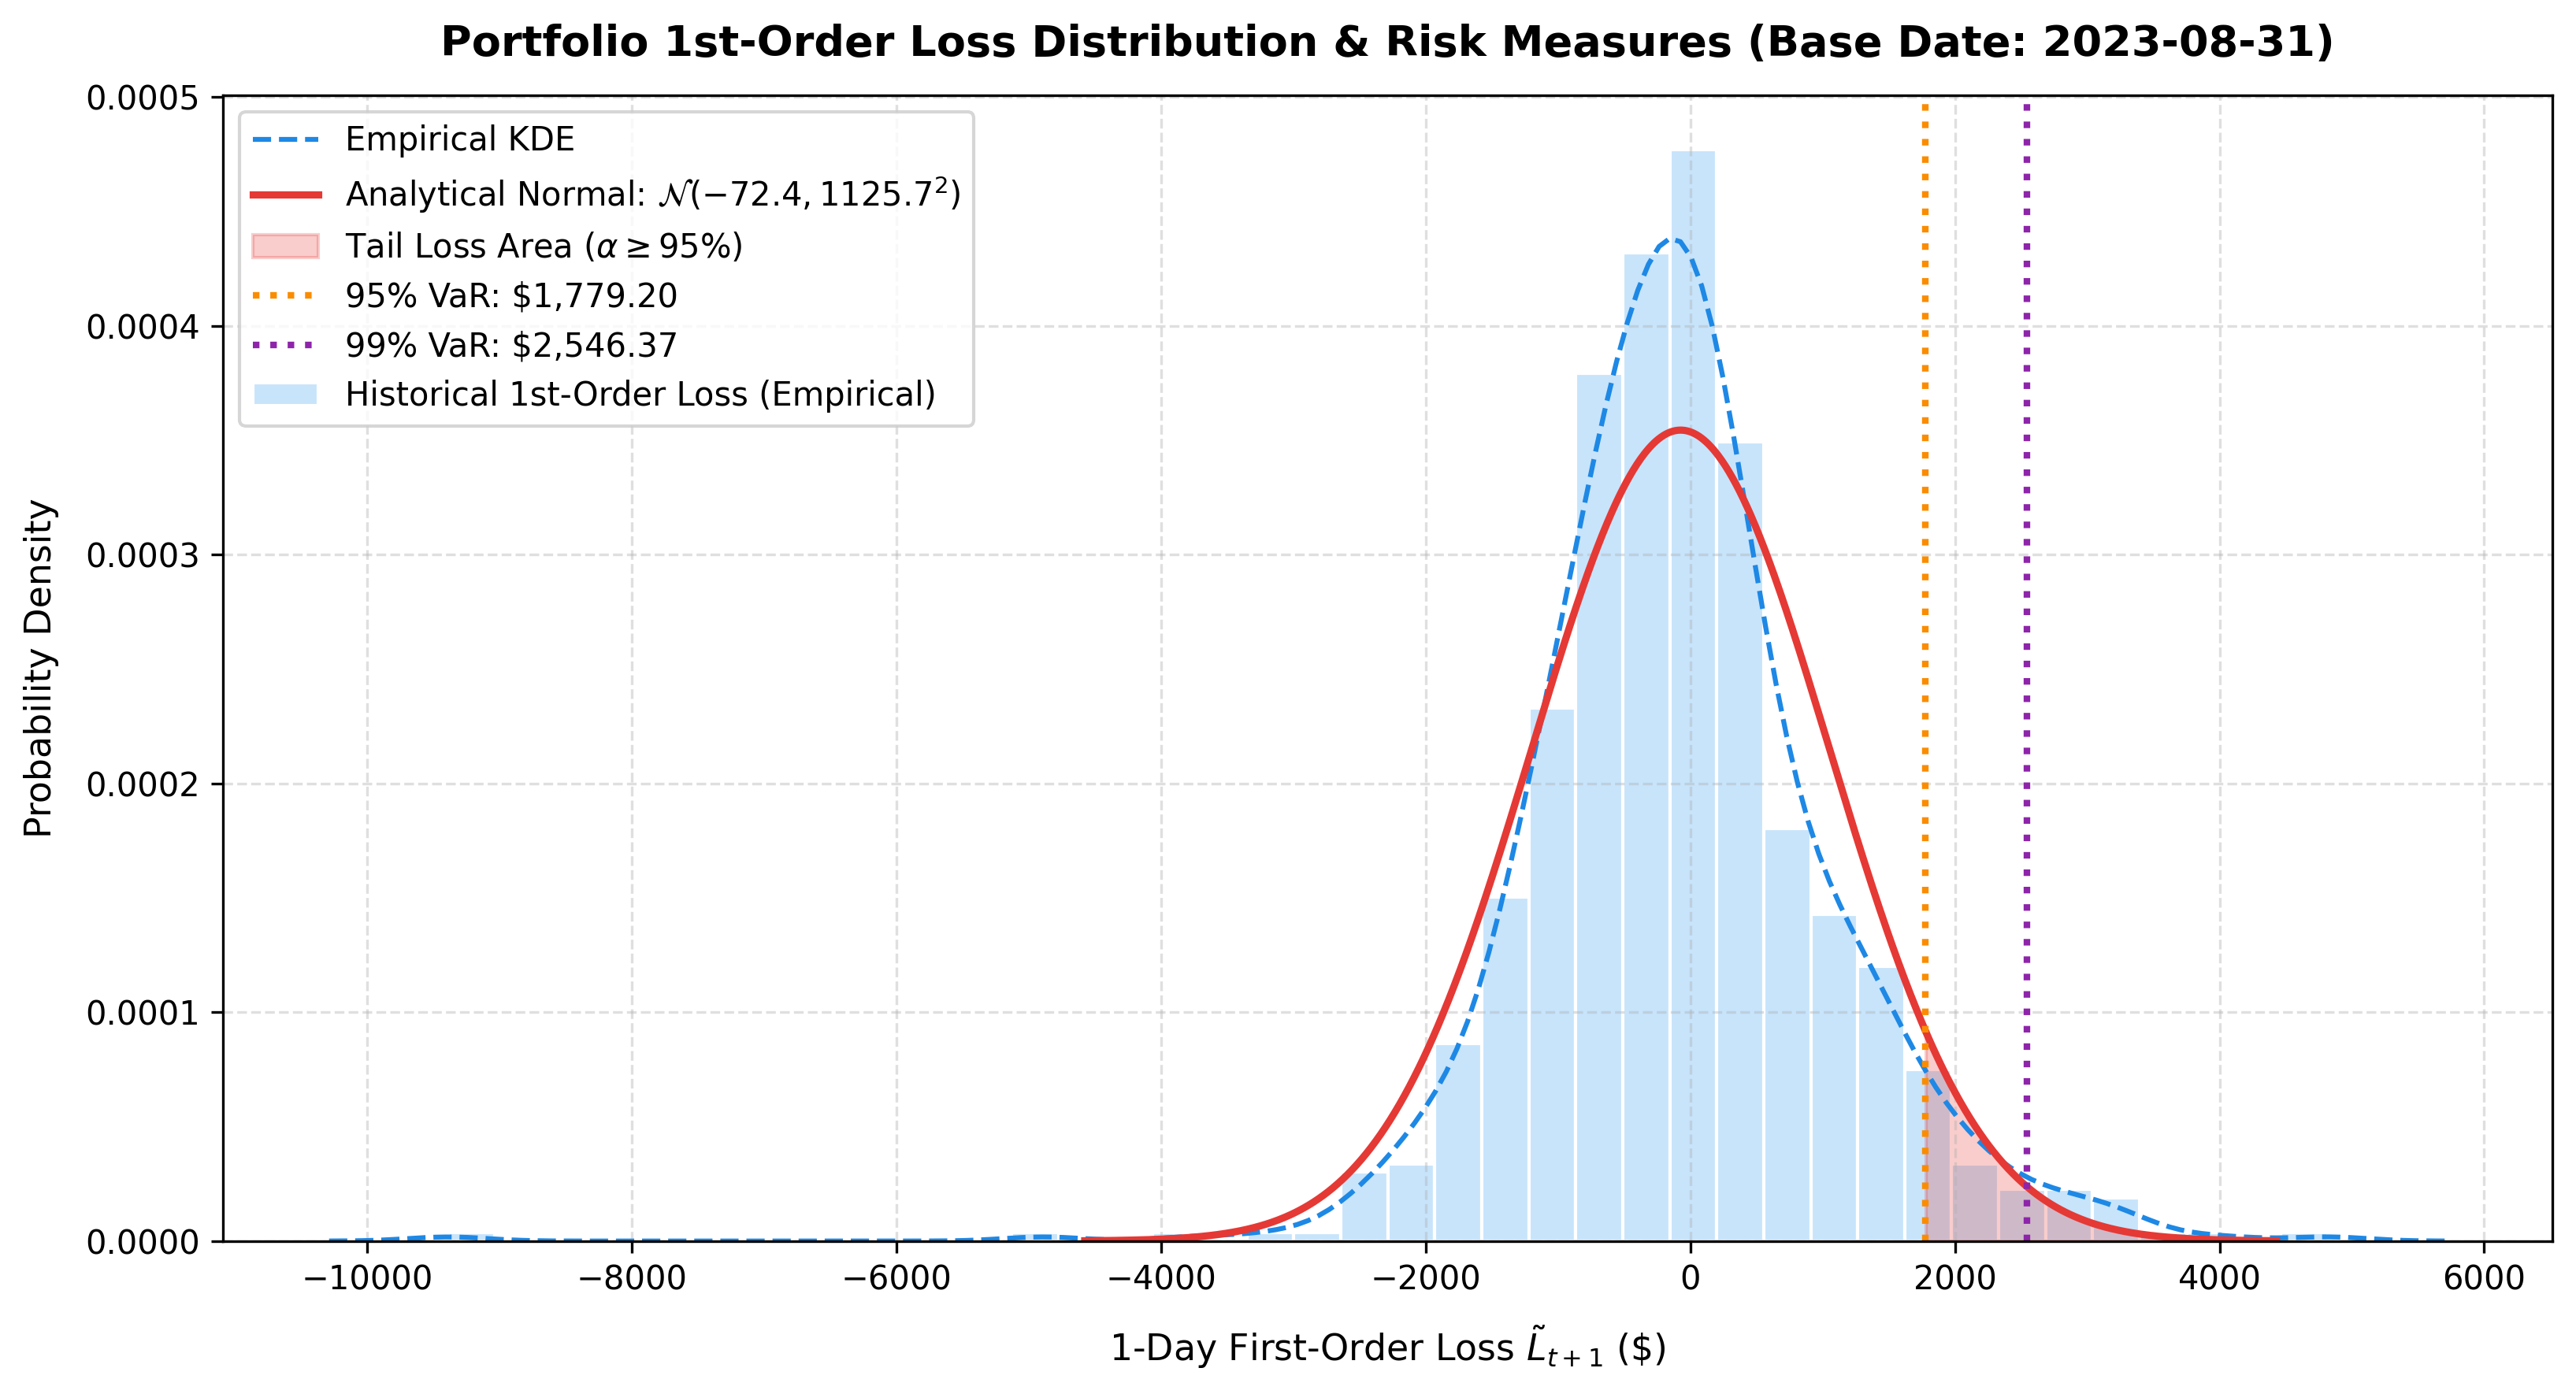

In [ ]:
# -------------------------------------------------------------
# 1. 计算历史样本序列对应的组合一阶近似损失序列
# -------------------------------------------------------------
# 对历史每一个样本交易日 s，计算近似损失 L_s = -b_t' * X_s
hist_losses = -X_matrix.dot(b_vec)

# -------------------------------------------------------------
# 2. 计算 95% 和 99% 的参数化解析 VaR
# -------------------------------------------------------------
alpha_95, alpha_99 = 0.95, 0.99
# VaR_alpha = mu_L + sigma_L * z_alpha
var_95 = loss_mean + loss_std * stats.norm.ppf(alpha_95)
var_99 = loss_mean + loss_std * stats.norm.ppf(alpha_99)


# -------------------------------------------------------------
# 3. 绘制损失分布密度图与 VaR 标注
# -------------------------------------------------------------
plt.figure(figsize=(11, 6), dpi=300)

# 生成理论正态分布横坐标区间
x_vals = np.linspace(loss_mean - 4 * loss_std, loss_mean + 4 * loss_std, 1000)
norm_pdf = stats.norm.pdf(x_vals, loc=loss_mean, scale=loss_std)

# 绘制历史模拟损失的经验密度直方图与核密度估计 (KDE)
sns.histplot(
    hist_losses,
    stat="density",
    bins=40,
    color="#90CAF9",
    edgecolor="white",
    alpha=0.5,
    label="Historical 1st-Order Loss (Empirical)",
)
sns.kdeplot(
    hist_losses,
    color="#1E88E5",
    linestyle="--",
    linewidth=1.5,
    label="Empirical KDE",
)

# 绘制参数法理论正态密度曲线
plt.plot(
    x_vals,
    norm_pdf,
    color="#E53935",
    linewidth=2.2,
    label=f"Analytical Normal: $\mathcal{{N}}({loss_mean:.1f}, {loss_std:.1f}^2)$",
)

# 填充尾部风险区域 (以 95% VaR 为例) - 修正这里
tail_mask = x_vals >= var_95
plt.fill_between(
    x_vals[tail_mask],
    norm_pdf[tail_mask],
    color="#E53935",
    alpha=0.25,
    label=r"Tail Loss Area ($\alpha \geq 95\%$)",  # 修正：简化 LaTeX
)

# 标注 VaR 阈值虚线
plt.axvline(
    var_95,
    color="#FB8C00",
    linestyle=":",
    linewidth=2,
    label=f"95% VaR: ${var_95:,.2f}",
)
plt.axvline(
    var_99,
    color="#8E24AA",
    linestyle=":",
    linewidth=2,
    label=f"99% VaR: ${var_99:,.2f}",
)

# 格式设置
plt.title(
    f"Portfolio 1st-Order Loss Distribution & Risk Measures (Base Date: {base_date.strftime('%Y-%m-%d')})",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
plt.xlabel(
    r"1-Day First-Order Loss $\tilde{L}_{t+1}$ (\$)", fontsize=11, labelpad=8
)
plt.ylabel("Probability Density", fontsize=11, labelpad=8)
plt.legend( frameon=True, fontsize=10)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

plt.show()